# 04 · Marketing-mix regression: what does the *next* VND of spend return?

Notebook 01 showed average ROAS by channel and hinted at diminishing returns. Average ROAS is
the wrong number for a budget decision — the question is the **marginal** return, and that
needs a model.

**Model.** A log-log regression of daily revenue on ad-stocked channel spend:

$$\log(\text{Revenue}_t) = \alpha + \sum_c \beta_c \log(1 + \text{Adstock}_c(t)) + \text{seasonality} + \text{calendar dummies} + \varepsilon_t$$

* **Log-log** so each β is an **elasticity** (a 1% spend increase → β% revenue increase), and
  diminishing returns are built in (β < 1).
* **Ad-stock** (geometric carry-over) because today's ads still convert tomorrow — the EDA showed
  the day after each sale ranking among the best days of the year.
* **Seasonality** as two Fourier harmonics rather than 11 month dummies (fewer parameters,
  smoother).

OLS is implemented in `src/stats_utils.py` with numpy so the notebook has no heavy dependencies;
it mirrors `statsmodels.OLS` and gives the same coefficient table.

**Data:** `data/raw/campaign_daily.csv`, paid channels only (Email is retention, not acquisition).

In [2]:
import sys
sys.path.insert(0, ".")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from src.stats_utils import ols, vif, adstock

plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold"})
PALETTE = {"Facebook Ads": "#2a78d6", "Google Ads": "#eb6834", "TikTok Ads": "#1baf7a", "Zalo OA": "#eda100", "Affiliate": "#008300"}
BLUE, MUTED = "#2a78d6", "#898781"

df = pd.read_csv("data/raw/campaign_daily.csv", parse_dates=["date"])
paid = df[df["channel"] != "Email"]
spend = paid.pivot_table(index="date", columns="channel", values="spend", aggfunc="sum")
revenue = df.groupby("date")["revenue"].sum().loc[spend.index]
channels = list(spend.columns)
spend.describe().loc[["mean", "min", "max"]].div(1e6).round(1)

channel,Affiliate,Facebook Ads,Google Ads,TikTok Ads,Zalo OA
mean,5.7,20.4,15.8,10.2,3.8
min,1.0,2.8,3.5,2.6,0.6
max,25.3,78.0,46.6,28.0,14.0


## 1. Choosing ad-stock decay rates
Decay is a hyper-parameter per channel. Rather than assume, pick the decays that maximise the
fit of the **full** model (all channels + seasonality controls), one channel at a time, cycling
until nothing changes — a small coordinate-descent over a 0.0–0.8 grid.

Why the full model and not one channel at a time: a heavily smoothed spend series looks like a
seasonal curve, so a single-channel search always "prefers" a high decay for the wrong reason.
With the seasonal terms in the model, the search has to earn its fit from spend timing.

In [4]:
t = np.arange(len(spend))
controls = pd.DataFrame({
    "weekend": (spend.index.weekday >= 5).astype(int),
    "sale_day": spend.index.strftime("%m-%d").isin(["11-11", "12-12", "06-06"]).astype(int),
    "sin_annual": np.sin(2 * np.pi * t / 365.25), "cos_annual": np.cos(2 * np.pi * t / 365.25),
    "sin_semi": np.sin(4 * np.pi * t / 365.25), "cos_semi": np.cos(4 * np.pi * t / 365.25),
}, index=spend.index)
y = np.log(revenue / 1e6)
grid = np.round(np.arange(0.0, 0.85, 0.05), 2)

def design(decays: dict) -> pd.DataFrame:
    Xc = pd.DataFrame({ch: np.log1p(adstock(spend[ch].to_numpy(), decays[ch]) / 1e6) for ch in channels}, index=spend.index)
    return pd.concat([Xc, controls], axis=1)

best = {ch: 0.3 for ch in channels}
for sweep in range(3):
    changed = False
    for ch in channels:
        scores = []
        for d in grid:
            trial = {**best, ch: float(d)}
            scores.append(ols(y, design(trial)).rsquared)
        pick = float(grid[int(np.argmax(scores))])
        changed |= pick != best[ch]
        best[ch] = pick
    if not changed:
        break
pd.Series(best, name="best_decay").to_frame().T

,Affiliate,Facebook Ads,Google Ads,TikTok Ads,Zalo OA
best_decay,0.35,0.5,0.2,0.65,0.1


The data-chosen decays line up with channel logic: **Zalo OA and Google** (messaging and search,
close to the purchase moment) decay fastest; **TikTok and Facebook** (upper-funnel video/social)
carry over longest, with Affiliate in between. These are used below.

## 2. Design matrix and fit

In [7]:
X = design(best)
model = ols(y, X)
print(f"n = {model.nobs}, R² = {model.rsquared:.3f}, adj. R² = {model.rsquared_adj:.3f}")
model.summary().round(4)

n = 365, R² = 0.877, adj. R² = 0.873


,coef,std_err,t,p_value,ci_2.5%,ci_97.5%
const,3.3956,0.0921,36.8786,0.0000,3.2145,3.5767
Affiliate,0.1169,0.0229,5.1136,0.0000,0.0719,0.1619
Facebook Ads,0.3197,0.0227,14.0721,0.0000,0.2751,0.3644
Google Ads,0.1544,0.0186,8.3006,0.0000,0.1178,0.1910
TikTok Ads,0.1210,0.0286,4.2326,0.0000,0.0648,0.1773
Zalo OA,0.0898,0.0180,5.0021,0.0000,0.0545,0.1251
weekend,-0.0045,0.0083,-0.5399,0.5896,-0.0209,0.0119
sale_day,-0.0209,0.0447,-0.4669,0.6409,-0.1089,0.0671
sin_annual,-0.0046,0.0057,-0.8108,0.4180,-0.0157,0.0065
cos_annual,0.0123,0.0058,2.1420,0.0329,0.0010,0.0236


**Reading the table.** All five channel elasticities are positive and significant at p < 0.001.
Facebook's elasticity (≈0.32) is the largest — a 10% increase in Facebook ad-stock is associated
with ≈3% more total daily revenue. Weekend, sale-day and most seasonal terms are not significant
*once spend is in the model*: the sale-day revenue spike is explained by the sale-day spend
spike, which is itself the finding from notebook 01 restated causally.

## 3. Does the model deserve to be trusted?
Three checks: multicollinearity (channels spend together in peak season), residual
autocorrelation (daily data), and the gain over a naive model.

In [10]:
vifs = vif(X[channels])
dw = np.sum(np.diff(model.resid) ** 2) / np.sum(model.resid ** 2)
naive = ols(y, pd.DataFrame({ch: np.log1p(spend[ch] / 1e6) for ch in channels}))
print("Variance inflation factors (rule of thumb: worry above 5):")
print(vifs.round(2).to_string())
print(f"\nDurbin-Watson = {dw:.2f}  (≈2 means no residual autocorrelation)")
print(f"Naive model (no ad-stock, no seasonality): R² = {naive.rsquared:.3f}  ->  this model: R² = {model.rsquared:.3f}")

Variance inflation factors (rule of thumb: worry above 5):
Affiliate       2.20
Facebook Ads    2.45
Google Ads      1.70
TikTok Ads      2.81
Zalo OA         1.58

Durbin-Watson = 2.18  (≈2 means no residual autocorrelation)
Naive model (no ad-stock, no seasonality): R² = 0.767  ->  this model: R² = 0.877


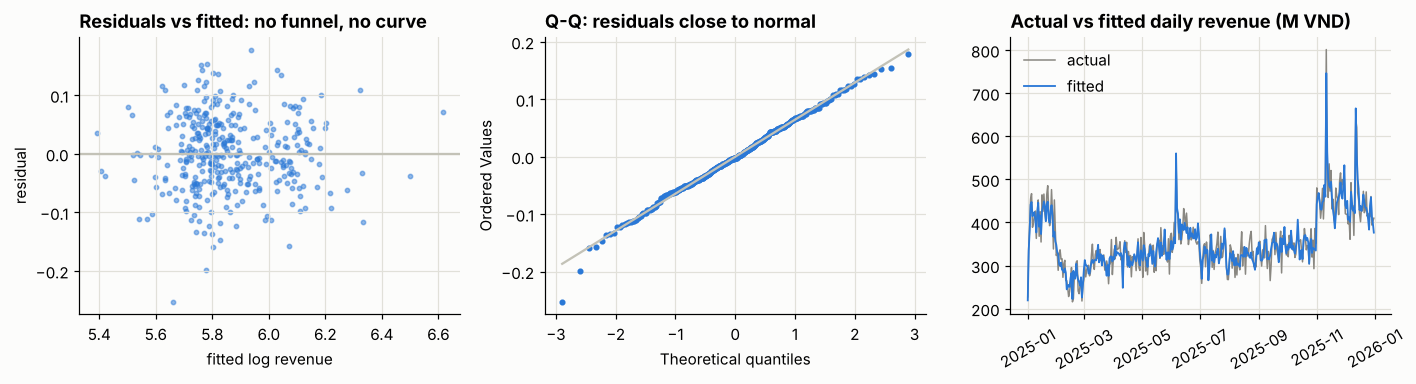

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].scatter(model.fitted, model.resid, s=8, color=BLUE, alpha=0.5)
axes[0].axhline(0, color="#c3c2b7"); axes[0].set_xlabel("fitted log revenue"); axes[0].set_ylabel("residual"); axes[0].set_title("Residuals vs fitted: no funnel, no curve")
stats.probplot(model.resid, plot=axes[1]); axes[1].get_lines()[0].set(color=BLUE, markersize=3); axes[1].get_lines()[1].set(color="#c3c2b7"); axes[1].set_title("Q-Q: residuals close to normal")
axes[2].plot(revenue.index, revenue / 1e6, color=MUTED, lw=1, label="actual")
axes[2].plot(revenue.index, np.exp(model.fitted), color=BLUE, lw=1.2, label="fitted")
axes[2].set_title("Actual vs fitted daily revenue (M VND)"); axes[2].legend(frameon=False); axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout()

VIFs are all below 3 (channels do move together seasonally, but not enough to destabilise the
coefficients), Durbin-Watson is ≈2.2, residuals are well behaved, and ad-stock + seasonality lift
R² from 0.77 to 0.88. Good enough to use for *relative* budget decisions; not good enough to
forecast a specific day.

## 4. Marginal ROAS — the number that should drive the budget
In a log-log model the marginal revenue per VND of channel $c$ at its average spend is
$\beta_c \times \dfrac{\overline{\text{Revenue}}}{\overline{\text{Spend}_c}}$.
Compare it with the average ROAS from notebook 01.

In [14]:
tbl = pd.DataFrame({
    "elasticity": model.params[channels],
    "avg_daily_spend_M": spend[channels].mean() / 1e6,
    "avg_ROAS_(last-click)": paid.groupby("channel")["revenue"].sum() / paid.groupby("channel")["spend"].sum(),
})
tbl["marginal_ROAS_(model)"] = tbl["elasticity"] * revenue.mean() / spend[channels].mean()
tbl["spend_share_%"] = 100 * spend[channels].sum() / spend[channels].sum().sum()
tbl = tbl.sort_values("marginal_ROAS_(model)", ascending=False)
tbl.round(2)

,elasticity,avg_daily_spend_M,avg_ROAS_(last-click),marginal_ROAS_(model),spend_share_%
Zalo OA,0.09,3.84,8.89,8.33,6.86
Affiliate,0.12,5.69,6.52,7.32,10.16
Facebook Ads,0.32,20.45,7.19,5.57,36.52
TikTok Ads,0.12,10.23,4.20,4.22,18.26
Google Ads,0.15,15.79,5.39,3.48,28.20


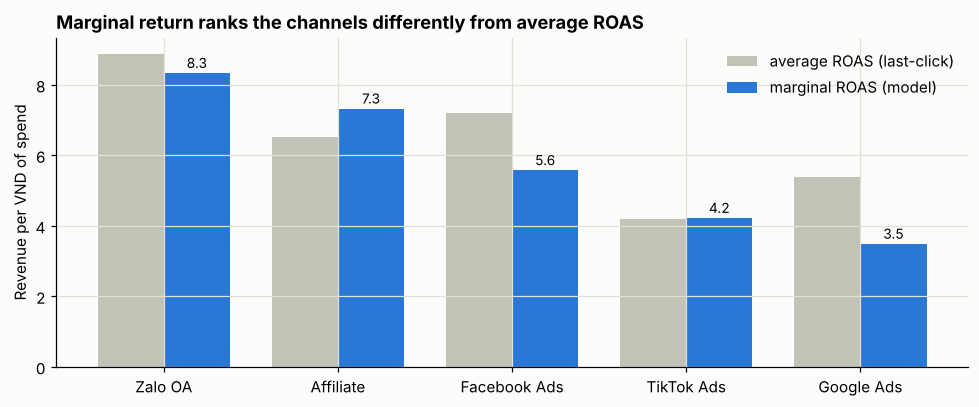

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(tbl)); w = 0.38
ax.bar(x - w / 2, tbl["avg_ROAS_(last-click)"], w, color="#c3c2b7", label="average ROAS (last-click)")
ax.bar(x + w / 2, tbl["marginal_ROAS_(model)"], w, color=BLUE, label="marginal ROAS (model)")
for i, v in enumerate(tbl["marginal_ROAS_(model)"]):
    ax.text(i + w / 2, v + 0.15, f"{v:.1f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(tbl.index); ax.set_ylabel("Revenue per VND of spend")
ax.set_title("Marginal return ranks the channels differently from average ROAS")
ax.legend(frameon=False)
plt.tight_layout()

Two channels change places when we move from average to marginal:

* **Zalo OA** has the highest marginal ROAS (~8.3) *and* the smallest budget share (~7%) — it is the
  clearest under-investment in the mix. **Affiliate** (~7.3) is the second.
* **Google Ads** has the lowest marginal ROAS (~3.5) despite a healthy average (5.4): the next VND
  of search spend buys lower-intent queries. It is the clearest candidate to fund a shift.
* **Facebook** is large and still productive at the margin (~5.6), though below its average ROAS
  of 7.2 — the first sign of saturation. Keep, don't grow.
* **TikTok** is ~4 on both measures; with 74% of its conversions being new customers (notebook 01),
  its true marginal value is higher than this revenue-only model shows.

## 5. Scenario: move 15% of Google's budget to Zalo OA
Same total spend. The model's prediction, with the caveat that Zalo's average daily spend would
rise ~60% — still inside the range the model has seen (its busiest days), but at a level it has
only seen in peak season.

In [18]:
def predict_revenue(spend_df: pd.DataFrame) -> pd.Series:
    Xs = X.copy()
    for ch in channels:
        Xs[ch] = np.log1p(adstock(spend_df[ch].to_numpy(), best[ch]) / 1e6)
    Xs.insert(0, "const", 1.0)
    return pd.Series(np.exp(Xs.to_numpy() @ model.params.to_numpy()) * 1e6, index=spend_df.index)  # back to VND

base_pred = predict_revenue(spend)
scenario = spend.copy()
shift = 0.15 * scenario["Google Ads"]
scenario["Google Ads"] -= shift
scenario["Zalo OA"] += shift
scen_pred = predict_revenue(scenario)

print(f"Total paid spend (both scenarios): {spend.sum().sum() / 1e9:,.2f} B VND")
print(f"Predicted annual revenue - current mix:  {base_pred.sum() / 1e9:,.2f} B VND")
print(f"Predicted annual revenue - reallocated:  {scen_pred.sum() / 1e9:,.2f} B VND  ({scen_pred.sum() / base_pred.sum() - 1:+.1%})")
print(f"Zalo OA average daily spend would rise from {spend['Zalo OA'].mean() / 1e6:.1f}M to {scenario['Zalo OA'].mean() / 1e6:.1f}M VND "
      f"(observed max: {spend['Zalo OA'].max() / 1e6:.1f}M)")

Total paid spend (both scenarios): 20.44 B VND
Predicted annual revenue - current mix:  129.82 B VND
Predicted annual revenue - reallocated:  131.56 B VND  (+1.3%)
Zalo OA average daily spend would rise from 3.8M to 6.2M VND (observed max: 14.0M)


## Recommendation

1. **Rebalance ~15% of Google Ads budget into Zalo OA**, in steps, watching Zalo's CPA weekly.
   The model predicts a ~+1.3% revenue gain at equal spend (≈1.7B VND a year). Because Zalo would
   run at peak-season spend levels all year, treat the first step as a test, not a forecast.
2. **Do not cut TikTok on ROAS grounds.** Its revenue-only marginal return understates a channel
   that supplies three-quarters new customers; evaluate it on 12-month customer value.
3. **Hold Facebook.** Largest elasticity, still productive at the margin.
4. **Stop over-spending on sale days.** The sale-day dummy is not significant once spend is
   controlled for: the extra revenue those days is bought, not given.

### Limitations
* Observational data; elasticities are associations under the model's assumptions. The budget
  shift above should be run as a geo- or time-split experiment where possible.
* Last-click revenue attribution is the dependent variable; it under-credits upper-funnel channels.
* No saturation curve beyond the log form; no competitor or price variables.
* One year of daily data — the seasonal terms are estimated from a single cycle.